# LTX-β neutral sources on the SOLEDGE3X plasma

### OpenEdge as the neutral code of a coupled edge simulation: one batch of every source, followed to extinction.

**Lithium** is sputtered by the H⁺ wall flux of the plasma solution (Bohdansky yield, Thompson energies) and ionized by ADAS rates.
**Hydrogen** is the same H⁺ flux recycled through the Li wall (TRIM reflection, thermal re-emission as H₂, R = 0.5) plus an H₂ puff of 6.1e20 atoms/s, with ionization, charge exchange and the H₂ → H₂⁺ → H + H⁺ chain.
**Output**: plasma-frame source moments and neutral densities on a 5 mm R–Z grid, positive = gain for the fluid. Reference values quoted in the text are the SOLEDGE3X-EIRENE tallies of the same run.

In [1]:
from pathlib import Path
import numpy as np, h5py
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm
from matplotlib.tri import Triangulation
%matplotlib inline

CASE = Path.cwd().resolve()
if CASE.name == "notebooks":
    CASE = CASE.parent
SRC = CASE / "output" / "ltx_li_sources.h5"
BG  = CASE / "input" / "plasma_ltx.h5"
assert SRC.exists(), f"{SRC} missing: run in.openedge then scripts/export_sources.py"
# the talk/paper style (talkstyle.style of the seed figures), at notebook font sizes
plt.rcParams.update({"font.family": "serif", "font.size": 14, "axes.labelsize": 14, "axes.titlesize": 14,
                     "legend.fontsize": 12, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
                     "xtick.minor.visible": True, "ytick.minor.visible": True,
                     "axes.linewidth": 0.8, "lines.linewidth": 1.3, "figure.dpi": 120, "legend.frameon": False,
                     "figure.constrained_layout.use": True})
C = {"blue": "#0072B2", "green": "#009E73", "orange": "#E69F00", "vermillion": "#D55E00", "purple": "#CC79A7", "sky": "#56B4E9"}

def wall_loop(path):
    pts, mode = {}, None
    for l in open(path):
        s = l.strip()
        if s.lower() == "points": mode = "p"; continue
        if s.lower() == "lines":  mode = "l"; continue
        if mode == "p" and s and s[0].isdigit():
            a = s.split(); pts[int(a[0])] = (float(a[2]), float(a[1]))   # (Z,R) -> (R,Z)
    xy = [pts[i] for i in sorted(pts)] + [pts[1]]
    return np.array([p[0] for p in xy]), np.array([p[1] for p in xy])

WR, WZ = wall_loop(CASE / "input" / "ltx_wall_axi.surf")

## Setup: SOLEDGE3X plasma

Electron density and temperatures of the plasma solution on its triangular mesh; the black line is the wall.

Text(0, 0.5, 'Z (m)')

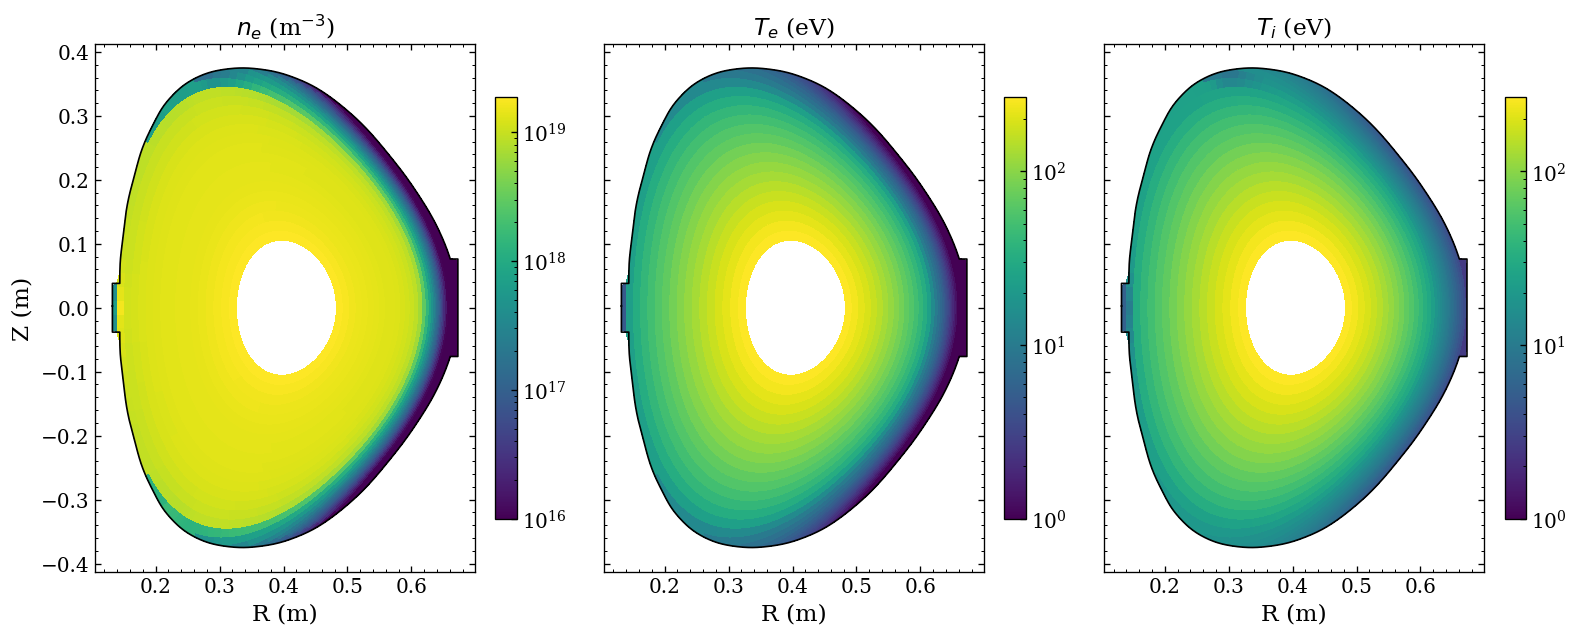

In [2]:
with h5py.File(BG) as f:
    tri = Triangulation(f["mesh/vtx_r"][...], f["mesh/vtx_z"][...], f["mesh/triangles"][...])
    ne, te, ti = f["mesh/dens_e"][...], f["mesh/temp_e"][...], f["mesh/temp_i"][...]
fig, ax = plt.subplots(1, 3, figsize=(13, 5.2), sharey=True)
for a, v, lab, norm in [(ax[0], ne, "$n_e$ (m$^{-3}$)", LogNorm(1e16, ne.max())),
                        (ax[1], te, "$T_e$ (eV)", LogNorm(1, te.max())),
                        (ax[2], ti, "$T_i$ (eV)", LogNorm(1, ti.max()))]:
    m = a.tripcolor(tri, v, norm=norm, cmap="viridis", shading="flat")
    a.plot(WR, WZ, "k-", lw=1); a.set_aspect("equal"); a.set_xlabel("R (m)"); a.set_title(lab)
    plt.colorbar(m, ax=a, shrink=0.8)
ax[0].set_ylabel("Z (m)")

## Setup: wall

H⁺ flux, impact energy and Li yield per wall element, from the SOLEDGE3X wall
tallies through `compute surface/physical/sputter`; the arc coordinate runs
along the wall from element 1. Reference: 1.88e19 Li/s sputtered by H⁺,
6.8e20 H⁺/s to the wall.

Li eroded by H+ 1.734e+19 Li/s;  H+ to the wall 6.829e+20 /s


Text(0.5, 1.0, 'Li source around the wall')

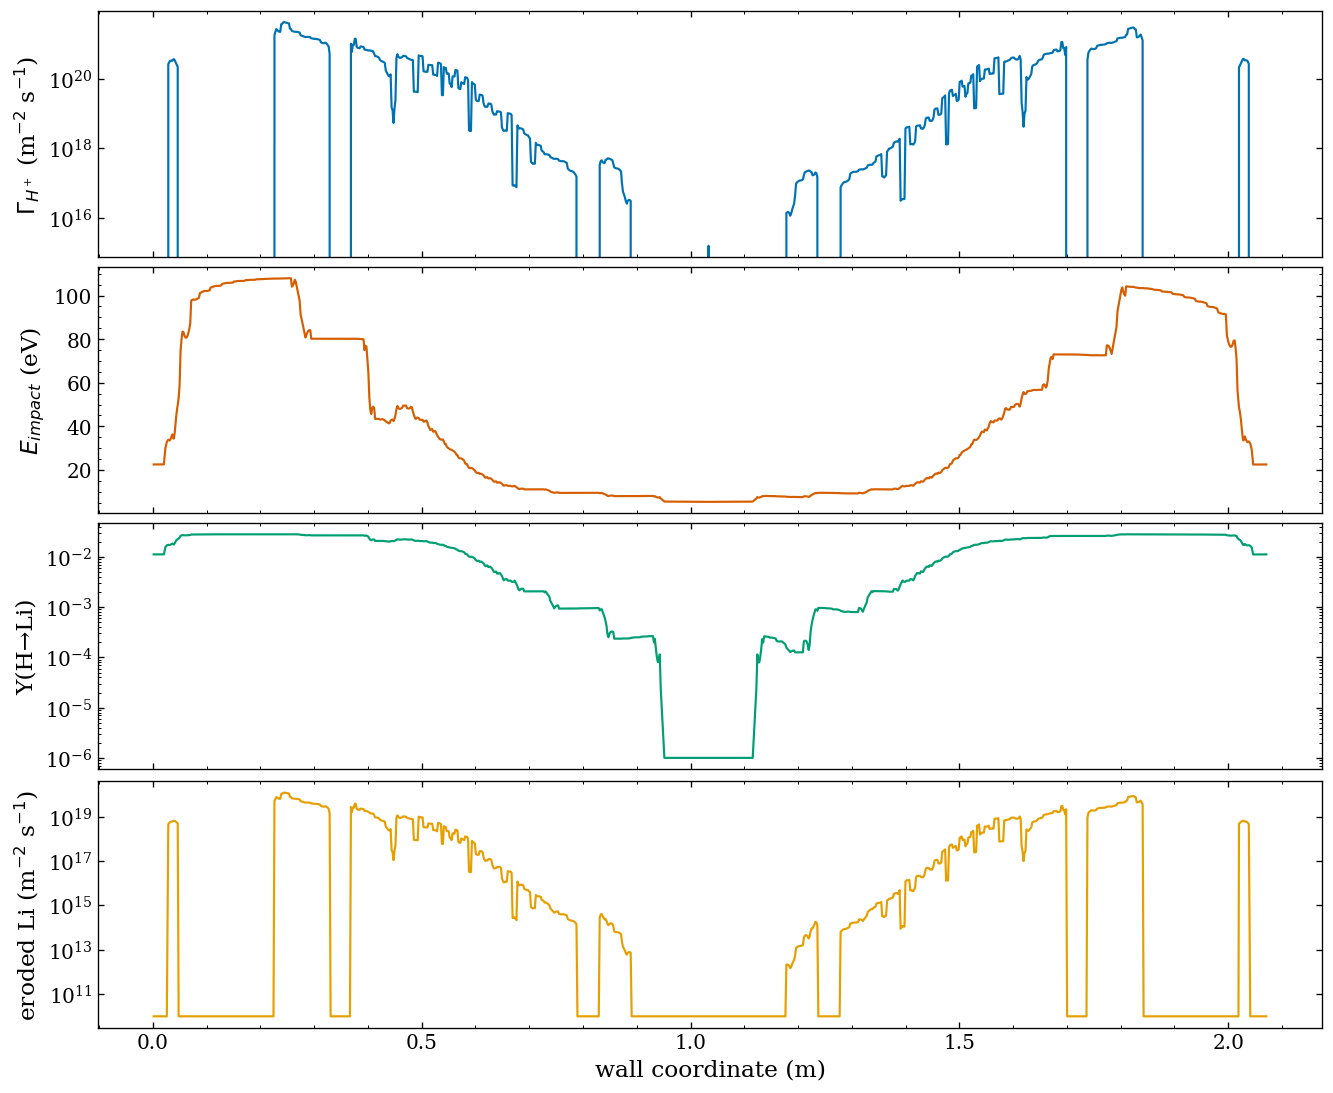

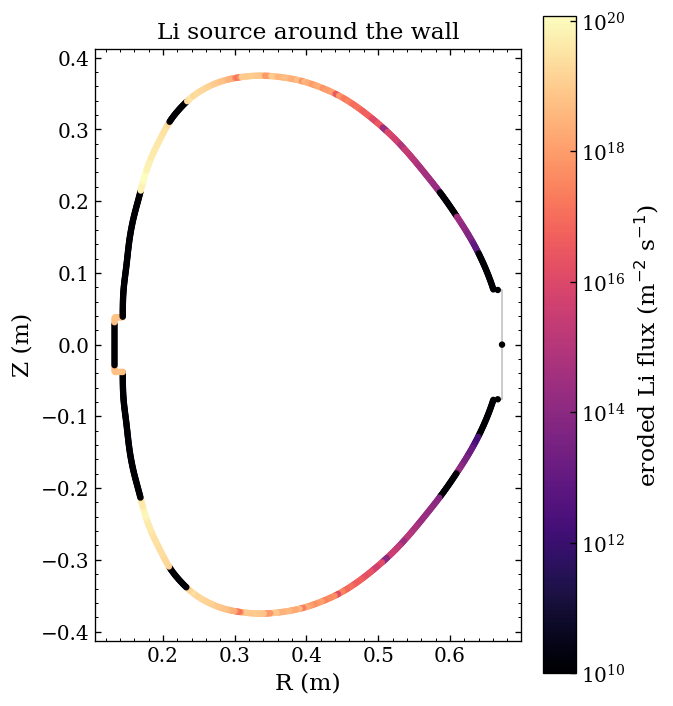

In [3]:
with h5py.File(SRC) as f:
    wall = {k: f["wall"][k][...] for k in f["wall"]}
s = wall["arc"]
fig, ax = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
ax[0].semilogy(s, wall["flux_Hplus"], color=C["blue"]); ax[0].set_ylabel("$\\Gamma_{H^+}$ (m$^{-2}$ s$^{-1}$)")
ax[1].plot(s, wall["E_impact_Hplus"], color=C["vermillion"]); ax[1].set_ylabel("$E_{impact}$ (eV)")
ax[2].semilogy(s, np.maximum(wall["yield_H_on_Li"], 1e-6), color=C["green"]); ax[2].set_ylabel("Y(H→Li)")
ax[3].semilogy(s, np.maximum(wall["erosion_flux"], 1e10), color=C["orange"]); ax[3].set_ylabel("eroded Li (m$^{-2}$ s$^{-1}$)")
ax[3].set_xlabel("wall coordinate (m)")
for a in ax: a.minorticks_on()
print(f"Li eroded by H+ {wall['erosion_rate'].sum():.3e} Li/s;  H+ to the wall {(wall['flux_Hplus']*wall['area']).sum():.3e} /s")
fig, a = plt.subplots(figsize=(5.5, 6))
m = a.scatter(wall["R"], wall["Z"], c=np.maximum(wall["erosion_flux"], 1e10), s=8, norm=LogNorm(), cmap="magma")
a.plot(WR, WZ, "-", color="0.7", lw=.8, zorder=0); a.set_aspect("equal"); a.set_xlabel("R (m)"); a.set_ylabel("Z (m)")
plt.colorbar(m, label="eroded Li flux (m$^{-2}$ s$^{-1}$)"); a.set_title("Li source around the wall")

## Load results

`output/ltx_li_sources.h5`, written by `scripts/export_sources.py` from the last dumps of the run.

In [4]:
with h5py.File(SRC) as f:
    r, z, V = f["r"][...], f["z"][...], f["cell_volume"][...]
    F = {k: f[k][...] for k in ["S_p", "S_m_r", "S_m_z", "S_m_phi", "S_m_par", "Q_e", "Q_i", "n_Li0", "psi_n"]}
    H = {k: f["H"][k][...] for k in f["H"] if k != "convergence"}
    conv = {k: f["convergence"][k][...] for k in f["convergence"]}
    convH = {k: f["H/convergence"][k][...] for k in f["H/convergence"]}
    totals = dict(f["totals"].attrs)
    wall = {k: f["wall"][k][...] for k in f["wall"]}
for k, v in totals.items():
    print(f"{k:20s} {v: .4e}" if isinstance(v, float) else f"{k:20s} {v}")

H_Q_e                -3.4901e+03
H_Q_i                -8.3314e+02
H_S_m_phi            -2.2295e-04
H_S_m_r               4.0188e-02
H_S_m_z              -1.3052e-03
H_S_p                 7.6238e+20
N_Li0                 9.3277e+13
Q_e                  -6.6245e+01
Q_i                   1.3481e+01
S_m_phi               1.0818e-05
S_m_r                 1.0992e-03
S_m_z                -1.4468e-04
S_p                   2.2590e+19
last_step            1800
wall_erosion_rate     1.7338e+19


## Results: lithium sources

Neutral Li density, the Li⁺ particle source (ionization), the electron energy
sink of that ionization, the kinetic energy the new ions bring, and the
parallel and toroidal momentum sources. Reference (SOLEDGE3X-EIRENE, same
plasma): 2.38e19 Li/s ionized, of which 0.57e19 from sputtering by H atoms.

lithium volume integrals: S_p 2.259e+19 Li/s, Q_e -6.624e+01 W, Q_i 1.348e+01 W, N_Li 9.328e+13 atoms


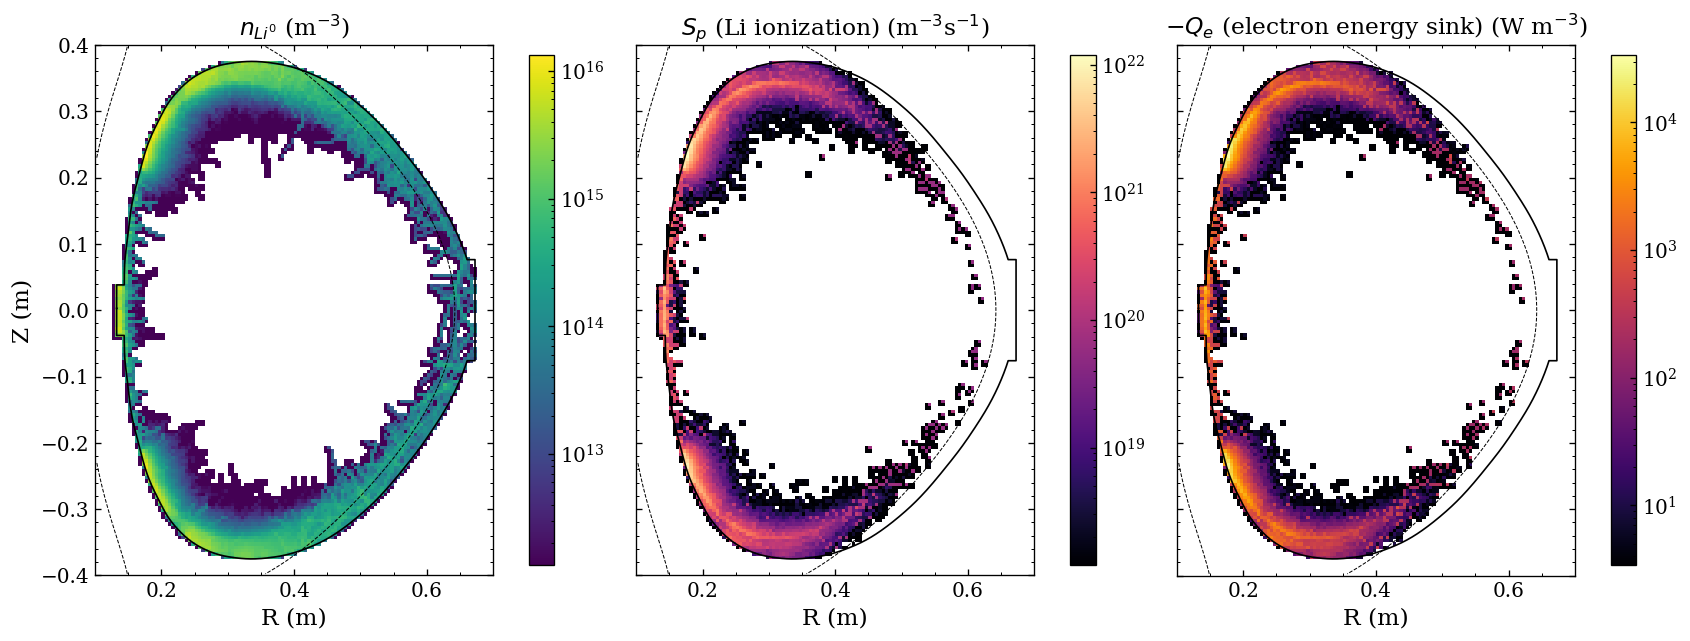

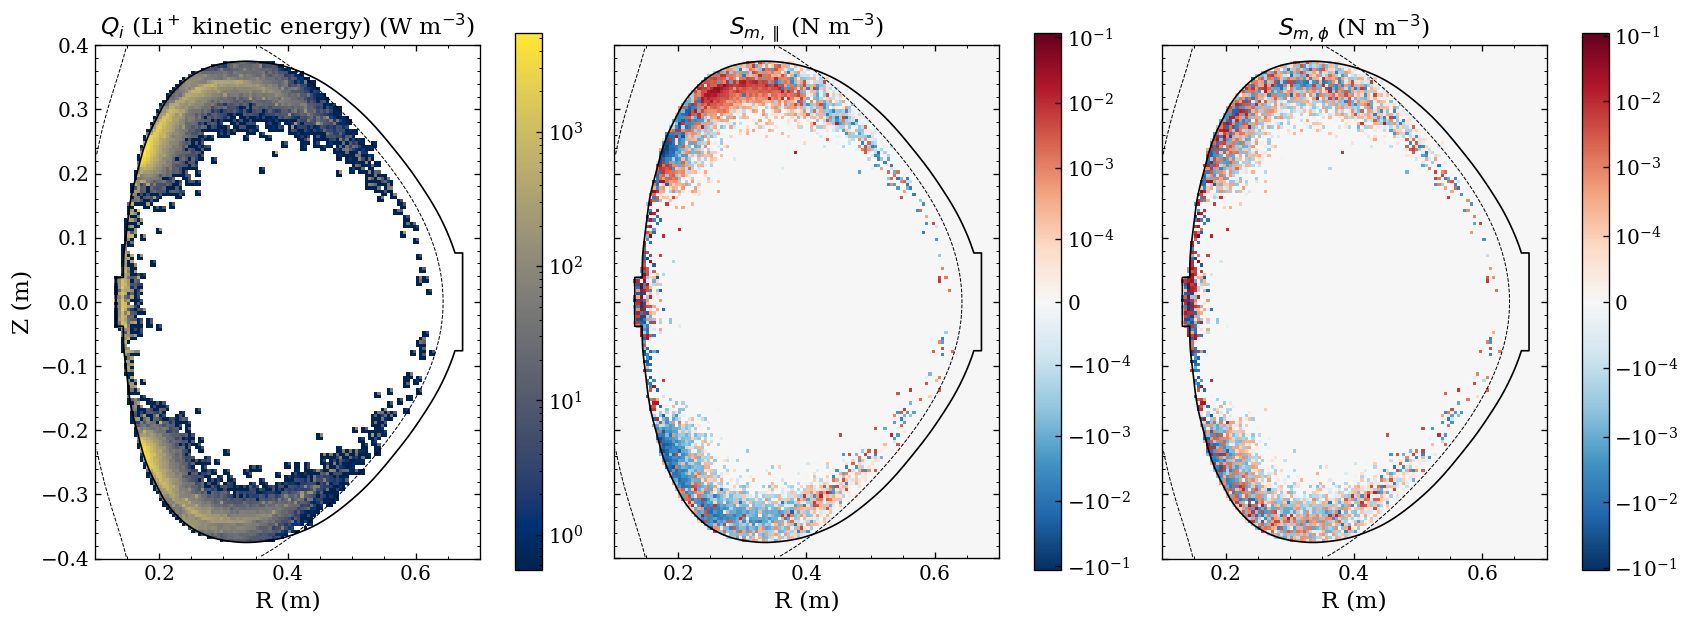

In [5]:
def rzmap(a, v, title, cmap="viridis", log=True, sym=False):
    v = np.ma.masked_invalid(v)
    if sym:
        vmax = np.nanmax(np.abs(v)); norm = SymLogNorm(linthresh=1e-3*vmax, vmin=-vmax, vmax=vmax)
        cmap = "RdBu_r"
    elif log:
        pos = v[v > 0]; norm = LogNorm(max(pos.max()*1e-4, pos.min()), pos.max()) if pos.size else None
        v = np.ma.masked_less_equal(v, 0)
    else:
        norm = None
    m = a.pcolormesh(r, z, v, norm=norm, cmap=cmap, shading="nearest")
    a.plot(WR, WZ, "k-", lw=1); a.contour(r, z, F["psi_n"], levels=[1.0], colors="k", linewidths=.6, linestyles="--")
    a.set_aspect("equal"); a.set_title(title); a.set_xlabel("R (m)")
    plt.colorbar(m, ax=a, shrink=0.85)

fig, ax = plt.subplots(1, 3, figsize=(14, 5.5), sharey=True)
rzmap(ax[0], F["n_Li0"], "$n_{Li^0}$ (m$^{-3}$)")
rzmap(ax[1], F["S_p"], "$S_p$ (Li ionization) (m$^{-3}$s$^{-1}$)", cmap="magma")
rzmap(ax[2], -F["Q_e"], "$-Q_e$ (electron energy sink) (W m$^{-3}$)", cmap="inferno")
ax[0].set_ylabel("Z (m)"); 
fig, ax = plt.subplots(1, 3, figsize=(14, 5.5), sharey=True)
rzmap(ax[0], F["Q_i"], "$Q_i$ (Li$^+$ kinetic energy) (W m$^{-3}$)", cmap="cividis")
rzmap(ax[1], F["S_m_par"], "$S_{m,\\parallel}$ (N m$^{-3}$)", sym=True)
rzmap(ax[2], F["S_m_phi"], "$S_{m,\\phi}$ (N m$^{-3}$)", sym=True)
ax[0].set_ylabel("Z (m)")
print("lithium volume integrals: S_p %.3e Li/s, Q_e %.3e W, Q_i %.3e W, N_Li %.3e atoms"
      % tuple(np.nansum(F[k]*V) for k in ("S_p", "Q_e", "Q_i", "n_Li0")))

## Results: hydrogen sources and neutral densities

Reference (SOLEDGE3X-EIRENE, same plasma): H⁺ source 7.42e20 /s of which
2.64e20 /s via H₂⁺, Q_e −3.28 kW, Q_i −0.87 kW.

hydrogen volume integrals: S_p 7.624e+20 /s, Q_e -3.490e+03 W, Q_i -8.331e+02 W, N_H 1.928e+15, N_H2 3.387e+15, N_H2+ 2.311e+14


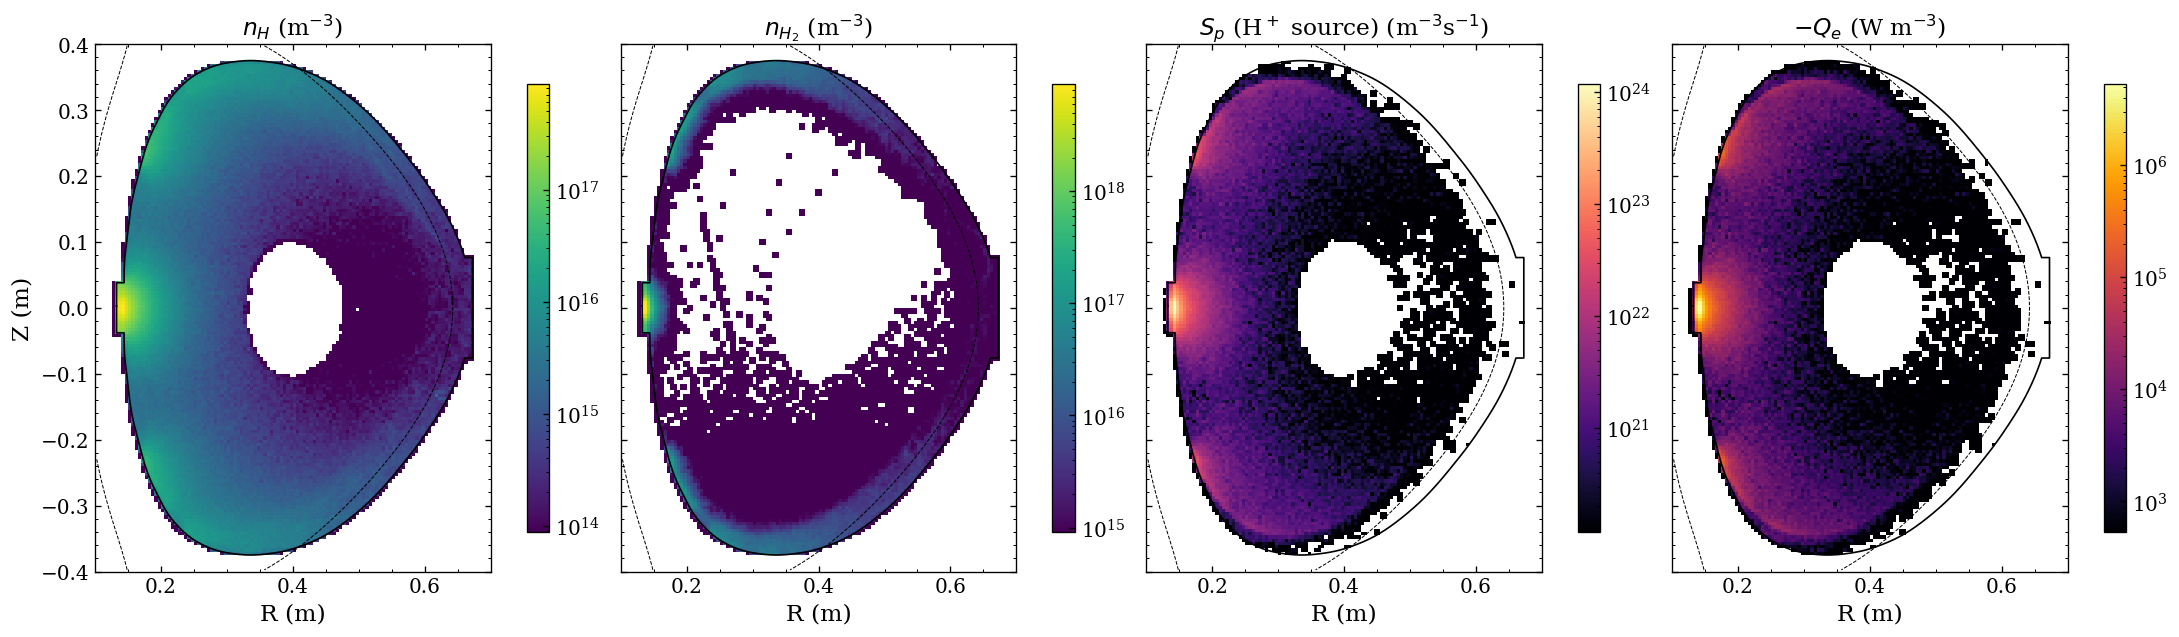

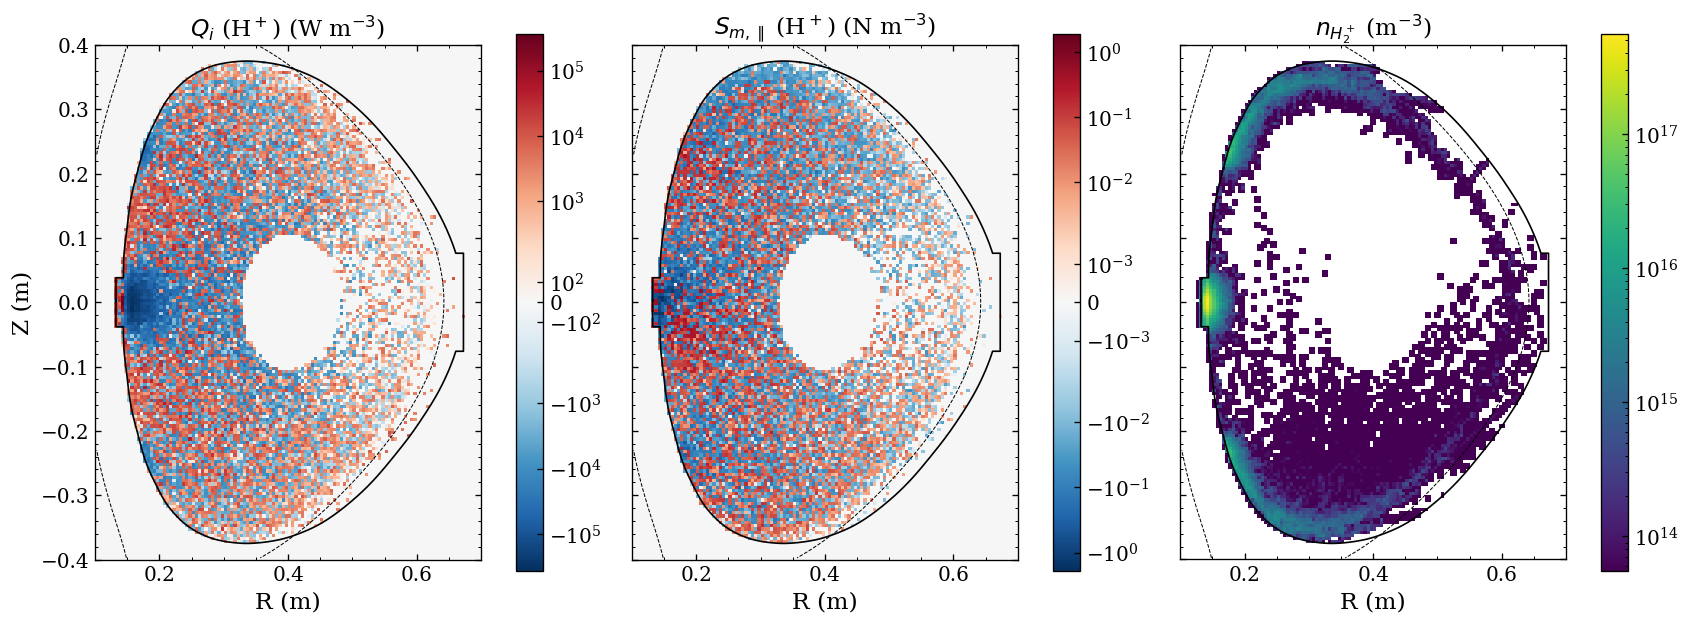

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 5.2), sharey=True)
rzmap(ax[0], H["n_H0"], "$n_{H}$ (m$^{-3}$)")
rzmap(ax[1], H["n_H2"], "$n_{H_2}$ (m$^{-3}$)")
rzmap(ax[2], H["S_p"], "$S_p$ (H$^+$ source) (m$^{-3}$s$^{-1}$)", cmap="magma")
rzmap(ax[3], -H["Q_e"], "$-Q_e$ (W m$^{-3}$)", cmap="inferno")
ax[0].set_ylabel("Z (m)"); fig, ax = plt.subplots(1, 3, figsize=(14, 5.5), sharey=True)
rzmap(ax[0], H["Q_i"], "$Q_i$ (H$^+$) (W m$^{-3}$)", sym=True)
rzmap(ax[1], H["S_m_par"], "$S_{m,\\parallel}$ (H$^+$) (N m$^{-3}$)", sym=True)
rzmap(ax[2], H["n_H2plus"], "$n_{H_2^+}$ (m$^{-3}$)")
ax[0].set_ylabel("Z (m)"); print("hydrogen volume integrals: S_p %.3e /s, Q_e %.3e W, Q_i %.3e W, N_H %.3e, N_H2 %.3e, N_H2+ %.3e"
      % tuple(np.nansum(H[k]*V) for k in ("S_p", "Q_e", "Q_i", "n_H0", "n_H2", "n_H2plus")))

## Convergence check

The batch is emitted at step 1 and followed until fewer than `nexhaust`
particles are left; each dump holds the source accumulated so far, so the
integrals must have flattened before the run ends.

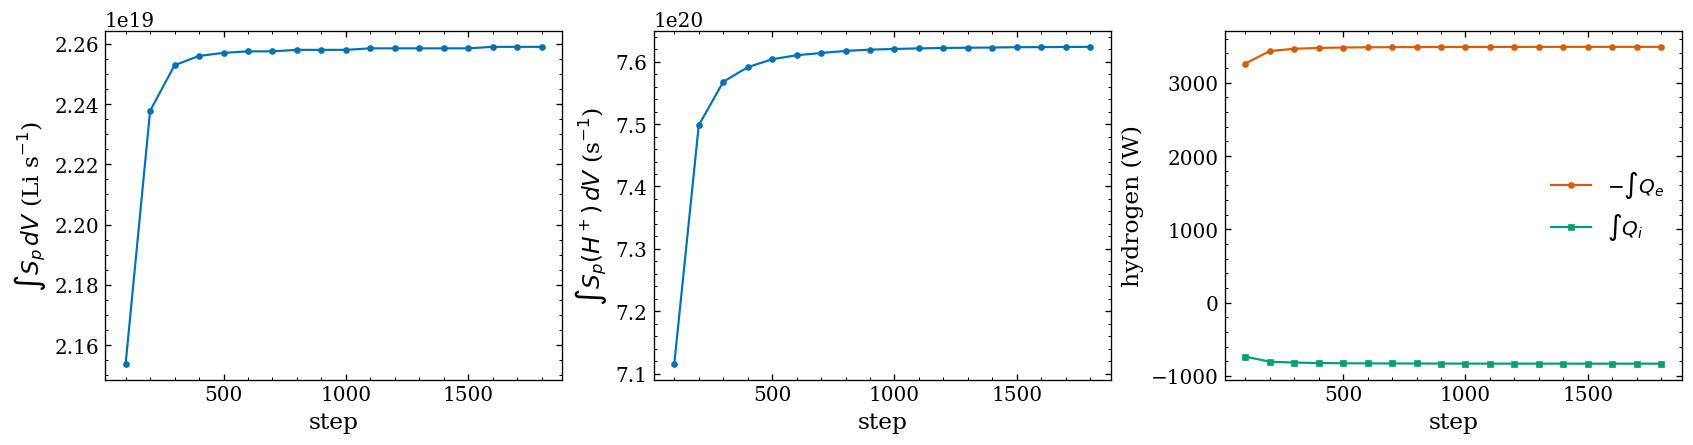

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(conv["step"], conv["int_S_p"], "o-", ms=3, color=C["blue"]); ax[0].set_ylabel("$\\int S_p\\,dV$ (Li s$^{-1}$)")
ax[1].plot(convH["step"], convH["int_S_p"], "o-", ms=3, color=C["blue"]); ax[1].set_ylabel("$\\int S_p(H^+)\\,dV$ (s$^{-1}$)")
ax[2].plot(convH["step"], -convH["int_Q_e"], "o-", ms=3, color=C["vermillion"], label="$-\\int Q_e$"); ax[2].plot(convH["step"], convH["int_Q_i"], "s-", ms=3, color=C["green"], label="$\\int Q_i$")
ax[2].set_ylabel("hydrogen (W)"); ax[2].legend()
for a in ax: a.set_xlabel("step"); a.minorticks_on()
